# TP4. Matrices et systèmes linéaires

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp4-matrices-gauss/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


**Version complétée avec assistance IA.** Solutions et explications adaptées des [corrigés de Christophe Guyeux](https://cours.gclab.fr/outils-fondamentaux/tp4-matrices-gauss/), sous licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). Les blocs du cours nécessaires aux exercices sont ajoutés. Exécuter les cellules dans l’ordre. Les temps mesurés dépendent de la machine. Relire les réponses et indiquer dans le README les vérifications réalisées personnellement.

**Rappel du cours / préparation pour la suite**

In [1]:
A = [[1, 2, 2],
     [1, 3, -2],
     [3, 5, 8]]

print(A[0])        
print(A[0][2])     
print(len(A), len(A[0]))   

[1, 2, 2]
2
3 3


## Exercice 1.1 : la transposée

Écrivez `transposee(A)` qui échange lignes et colonnes.

**Résultat attendu :** la transposée de `[[1, 2, 3], [4, 5, 6]]` est
`[[1, 4], [2, 5], [3, 6]]`.


In [2]:
def transposee(A):

    lignes = len(A)
    colonnes = len(A[0])
    return [[A[i][j] for i in range(lignes)] for j in range(colonnes)]

print(transposee([[1, 2, 3], [4, 5, 6]]))

[[1, 4], [2, 5], [3, 6]]


Notez l'ordre des deux boucles : la boucle extérieure engendre les lignes du
résultat, donc elle parcourt les colonnes de A. Inverser les deux donne une
matrice de la bonne taille mais fausse, erreur difficile à repérer sur une
matrice carrée. Testez toujours sur une matrice rectangulaire, où une erreur
de dimension saute aux yeux.

## Exercice 2.1 : produit à la main

Écrivez `produit(A, B)`, et vérifiez sur un exemple que vous savez calculer de tête.

**Résultat attendu :** multiplier une matrice par l'identité la laisse inchangée.


In [3]:
def produit(A, B):

    n, p = len(A), len(A[0])
    if len(B) != p:
        raise ValueError("dimensions incompatibles")
    q = len(B[0])
    C = [[0] * q for _ in range(n)]
    for i in range(n):
        for j in range(q):
            somme = 0
            for k in range(p):
                somme = somme + A[i][k] * B[k][j]
            C[i][j] = somme
    return C

identite = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
A = [[1, 2, 2], [1, 3, -2], [3, 5, 8]]
print(produit(A, identite) == A)
print(produit([[1, 2], [3, 4]], [[0, 1], [1, 0]]))

True
[[2, 1], [4, 3]]


Attention au piège de l'initialisation : [[0] * q] * n semble équivalent à la
ligne écrite ci-dessus, mais crée n références vers la même ligne. Modifier
C[0][0] modifierait alors toutes les lignes à la fois. C'est l'une des erreurs
les plus coûteuses en temps de débogage de toute la première année.

## Exercice 2.2 : mesurer le coût cubique

Mesurez le temps de `produit` sur deux matrices carrées aléatoires de taille 40, 80
puis 120. Que devient le temps quand la taille double ?

**Résultat attendu :** le temps est multiplié par environ 8 quand la taille double.


In [4]:
import random
import time

random.seed(42)

def matrice_aleatoire(n):
    return [[random.random() for _ in range(n)] for _ in range(n)]

for n in (40, 80, 120):
    A = matrice_aleatoire(n)
    B = matrice_aleatoire(n)
    debut = time.perf_counter()
    produit(A, B)
    print(f"n = {n:>3} : {time.perf_counter() - debut:.4f} s")

n =  40 : 0.0034 s
n =  80 : 0.0268 s
n = 120 : 0.0866 s


Trois boucles imbriquées de longueur \( n \) font \( n^{3} \) multiplications :
doubler \( n \) multiplie le travail par \( 2^{3} = 8 \). Sur \( n = 1000 \), il
faudrait un milliard d'opérations, soit plusieurs minutes en Python pur. C'est
précisément pour cela que numpy existe.

**Rappel du cours / préparation pour la suite**

In [5]:
import numpy as np

A = np.array([[1.0, 2.0, 2.0],
              [1.0, 3.0, -2.0],
              [3.0, 5.0, 8.0]])
b = np.array([2.0, -1.0, 8.0])

print(A.shape)
print(A.T)          
print(A @ A)        
print(A * A)        

(3, 3)
[[ 1.  1.  3.]
 [ 2.  3.  5.]
 [ 2. -2.  8.]]
[[  9.  18.  14.]
 [ -2.   1. -20.]
 [ 32.  61.  60.]]
[[ 1.  4.  4.]
 [ 1.  9.  4.]
 [ 9. 25. 64.]]


## Exercice 3.1 : le rapport de temps

Reprenez la mesure de l'exercice 2.2 pour `n = 120`, et comparez au produit numpy des
mêmes matrices.

**Résultat attendu :** numpy est plus rapide de deux à trois ordres de grandeur.


In [6]:
n = 120
A = matrice_aleatoire(n)
B = matrice_aleatoire(n)

debut = time.perf_counter()
produit(A, B)
t_python = time.perf_counter() - debut

An, Bn = np.array(A), np.array(B)
debut = time.perf_counter()
An @ Bn
t_numpy = time.perf_counter() - debut

print(f"python pur {t_python:.4f} s")
print(f"numpy      {t_numpy:.6f} s")
print("rapport :", round(t_python / max(t_numpy, 1e-9)))

python pur 0.0823 s
numpy      0.000627 s
rapport : 131


Ce rapport explique pourquoi tout le calcul scientifique en Python passe par
numpy. Cela ne dispense pas d'avoir écrit le produit à la main une fois : c'est en
l'écrivant qu'on comprend le coût cubique, et donc pourquoi multiplier deux
matrices de dix mille lignes n'est pas une opération anodine, même avec numpy.

## Exercice 4.1 : élimination et remontée

Écrivez `resoudre(A, b)` qui résout le système par le pivot de Gauss avec pivot
partiel, et testez-la sur le système de l'étape 1.

**Résultat attendu :** la solution est $(3,\, -1,\, 0{,}5)$, et $A x$
redonne bien $b$.


In [7]:
def resoudre(A, b, tolerance=1e-14):

    n = len(A)
    
    M = [list(A[i]) + [b[i]] for i in range(n)]

    for k in range(n):
        
        meilleure = max(range(k, n), key=lambda i: abs(M[i][k]))
        if abs(M[meilleure][k]) <= tolerance:
            raise ValueError("systeme singulier ou mal pose")
        M[k], M[meilleure] = M[meilleure], M[k]

        
        for i in range(k + 1, n):
            facteur = M[i][k] / M[k][k]
            for j in range(k, n + 1):
                M[i][j] = M[i][j] - facteur * M[k][j]

    
    x = [0.0] * n
    for i in range(n - 1, -1, -1):
        somme = M[i][n]
        for j in range(i + 1, n):
            somme = somme - M[i][j] * x[j]
        x[i] = somme / M[i][i]
    return x

A = [[1, 2, 2], [1, 3, -2], [3, 5, 8]]
b = [2, -1, 8]
x = resoudre(A, b)
print([round(v, 10) for v in x])


verif = [sum(A[i][j] * x[j] for j in range(3)) for i in range(3)]
print([round(v, 10) for v in verif])

[3.0, -1.0, 0.5]
[2.0, -1.0, 8.0]


Trois points à retenir. On travaille sur une copie : une fonction qui abîme
ses arguments est une source de bogues inépuisable. On construit la matrice
augmentée \( [A \mid b] \), ce qui évite de faire les mêmes opérations deux fois
sur deux objets séparés. Et on vérifie le résultat en recalculant \( Ax \), plutôt
qu'en relisant le code.

Le seuil tolerance mérite un mot. Avec des flottants, un pivot « nul » ne vaut
jamais exactement 0.0 : c'est un résidu d'arrondis, de l'ordre de
\( 10^{-16} \). Comparer à zéro laisserait passer une matrice singulière, et la
remontée diviserait par ce résidu pour produire des valeurs absurdes. On compare
donc à un petit seuil, et on le laisse réglable : l'étape 8 montrera un cas où il
faut le mettre à zéro.

## Exercice 4.2 : confronter à numpy

Comparez votre solution à celle de `numpy.linalg.solve` sur un système aléatoire de
taille 50.

**Résultat attendu :** les deux solutions coïncident à $10^{-9}$ près.


In [8]:
random.seed(7)
n = 50
A = matrice_aleatoire(n)
b = [random.random() for _ in range(n)]

mienne = resoudre(A, b)
celle_de_numpy = np.linalg.solve(np.array(A), np.array(b))

ecart = max(abs(mienne[i] - celle_de_numpy[i]) for i in range(n))
print("ecart maximal :", ecart)
print(ecart < 1e-9)

ecart maximal : 2.984279490192421e-13
True


Les deux implémentations font le même travail ; celle de numpy est écrite en
Fortran optimisé depuis quarante ans, mais l'algorithme est le vôtre. Un écart de
l'ordre de \( 10^{-13} \) est normal : ce sont les arrondis du TP1, qui n'ont pas
disparu.

**Rappel du cours / préparation pour la suite**

In [9]:
def hilbert(n):
    return np.array([[1.0 / (i + j + 1) for j in range(n)] for i in range(n)])

n = 12
H = hilbert(n)
x_vrai = np.ones(n)          
b = H @ x_vrai               

x_solve = np.linalg.solve(H, b)
x_inverse = np.linalg.inv(H) @ b

print("erreur avec solve   :", float(np.max(np.abs(x_solve - x_vrai))))
print("erreur avec inv @ b :", float(np.max(np.abs(x_inverse - x_vrai))))
print("conditionnement     : {:.3e}".format(float(np.linalg.cond(H))))

erreur avec solve   : 0.6961070342706484
erreur avec inv @ b : 21.0
conditionnement     : 1.808e+16


## Exercice 5.1 : lire le résultat

Exécutez le bloc ci-dessus et commentez. Quelle méthode donne la solution la plus
proche de la vraie ? Que vaut le conditionnement, et qu'est-ce que cela signifie ?


Les chiffres parlent d'eux-mêmes. Toutes les composantes de la vraie solution
valent 1. solve se trompe d'environ 0,7, et inv suivi d'un produit d'environ
21. La seconde méthode est donc à peu près trente fois pire que la première, et
aucune des deux ne donne un résultat utilisable.

La cause est le conditionnement, ici de l'ordre de \( 1{,}8 \times 10^{16} \).
Ce nombre mesure de combien une petite perturbation des données peut perturber la
solution. Quand il approche \( 10^{16} \), soit l'inverse de la précision des
flottants, plus aucun chiffre du résultat n'est fiable, et aucun algorithme ne
peut y remédier : c'est le problème lui-même qui est mal posé, pas votre
programme. Refaites l'essai avec n = 10 : le conditionnement tombe à
\( 1{,}6 \times 10^{13} \), les erreurs à \( 1{,}7 \times 10^{-4} \) et
\( 5{,}5 \times 10^{-3} \), et l'écart de trente entre les deux méthodes,
lui, demeure.

Retenez la règle pratique : pour résoudre un système, on écrit toujours
np.linalg.solve(A, b), jamais np.linalg.inv(A) @ b.

**Rappel du cours / préparation pour la suite**

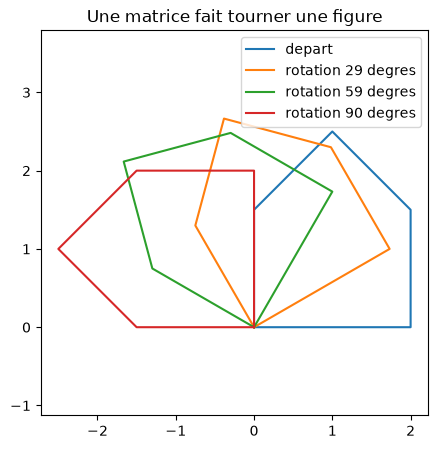

In [10]:
import matplotlib.pyplot as plt

def rotation(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s], [s, c]])


maison = np.array([[0, 0], [2, 0], [2, 1.5], [1, 2.5], [0, 1.5], [0, 0]]).T

plt.figure(figsize=(5, 5))
plt.plot(maison[0], maison[1], label="depart")
for angle in (np.pi / 6, np.pi / 3, np.pi / 2):
    image = rotation(angle) @ maison
    plt.plot(image[0], image[1], label=f"rotation {int(np.degrees(angle))} degres")
plt.axis("equal")
plt.legend()
plt.title("Une matrice fait tourner une figure")
plt.show()

## Exercice 6.1 : composer deux transformations

Vérifiez numériquement que faire tourner de 30 degrés puis de 60 degrés revient à
faire tourner de 90 degrés, autrement dit que
$R(60°) \cdot R(30°) = R(90°)$.


In [11]:
gauche = rotation(np.pi / 3) @ rotation(np.pi / 6)
droite = rotation(np.pi / 2)
print(np.allclose(gauche, droite))
print(np.round(droite, 10))

True
[[ 0. -1.]
 [ 1.  0.]]


np.allclose est le math.isclose du TP1, appliqué à un tableau entier : encore
une fois, on ne compare pas des flottants avec ==. Le produit de matrices
compose les transformations, et l'ordre compte en général, même si deux
rotations planes commutent exceptionnellement.

## Exercice 7.1 : déterminant par Gauss

Écrivez `determinant(A)` en reprenant l'élimination de `resoudre`, sans second membre :
multipliez les pivots successifs, et changez le signe à chaque échange de lignes.
Comparez à `np.linalg.det`.

**Résultat attendu :** le déterminant de la matrice de l'étape 1 vaut `-2`, et celui
de `[[1, 2], [2, 4]]` vaut `0`.


In [12]:
def determinant(A):

    n = len(A)
    M = [list(ligne) for ligne in A]
    det = 1.0
    for k in range(n):
        meilleure = max(range(k, n), key=lambda i: abs(M[i][k]))
        if abs(M[meilleure][k]) < 1e-14:
            return 0.0
        if meilleure != k:
            M[k], M[meilleure] = M[meilleure], M[k]
            det = -det
        det = det * M[k][k]
        for i in range(k + 1, n):
            facteur = M[i][k] / M[k][k]
            for j in range(k, n):
                M[i][j] = M[i][j] - facteur * M[k][j]
    return det

A = [[1, 2, 2], [1, 3, -2], [3, 5, 8]]
print(determinant(A), float(np.linalg.det(np.array(A, dtype=float))))
print(determinant([[1, 2], [2, 4]]))

-2.000000000000001 -2.0000000000000013
0.0


Le coût est celui de l'élimination, de l'ordre de \( n^{3} \) opérations. La
formule du déterminant que l'on apprend en cours, par développement suivant une
ligne, coûte \( n! \) opérations : pour \( n = 20 \), c'est deux mille milliards
de milliards, contre huit mille pour Gauss. Ne développez jamais un déterminant
au delà de la taille 3, ni à la main ni en machine.

## Exercice 8.1 : Hilbert vaincue

Construisez la matrice de Hilbert de taille 12 avec des `Fraction(1, i + j + 1)`, le
second membre `b` comme somme des lignes, pour que la solution soit le vecteur de 1,
puis appelez **votre** fonction `resoudre` de l'étape 4 dessus. Le premier essai échoue
avec « système singulier ». Comprenez pourquoi avant de lire le corrigé, puis corrigez.

**Résultat attendu :** exactement `[1, 1, ..., 1]`, douze fois `Fraction(1, 1)`, là
où `solve` se trompait de 0,7.


In [13]:
from fractions import Fraction

def hilbert_exacte(n):
    return [[Fraction(1, i + j + 1) for j in range(n)] for i in range(n)]

n = 12
H_exacte = hilbert_exacte(n)
b_exact = [sum(ligne) for ligne in H_exacte]

try:
    resoudre(H_exacte, b_exact)
except ValueError as erreur:
    print("premier essai :", erreur)

x_exact = resoudre(H_exacte, b_exact, tolerance=0)
print(x_exact)
print(all(v == 1 for v in x_exact))

premier essai : systeme singulier ou mal pose
[Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1)]
True


Le premier essai échoue parce que le dernier pivot vaut exactement
\( 1/170\,392\,979\,877\,120 \), soit environ \( 5{,}9 \times 10^{-15} \) :
un nombre parfaitement non nul, que le seuil de \( 10^{-14} \), conçu pour
écarter le bruit d'arrondi des flottants, prend pour du bruit. Sur des fractions,
il n'y a pas de bruit : le seul pivot à refuser est le zéro exact, d'où
tolerance=0. C'est le même algorithme, le même code, et un résultat parfait ;
seule la notion de « nul » a changé avec le type des nombres.

Regardez le prix. Les dénominateurs des coefficients atteignent seize chiffres
pour \( n = 12 \), et une soixantaine pour \( n = 40 \), qui se résout tout de
même en un dixième de seconde parce que la matrice est petite et très
structurée. Sur un système de mille inconnues issu de mesures réelles, les
fractions deviendraient ingérables. Les flottants ne sont pas un défaut de
conception, ils sont un compromis : rapides et à taille fixe, au prix d'un
arrondi que l'on doit savoir surveiller.

## Exercice 9.1 : l'ordre compte

Écrivez `translation(tx, ty)` et `rotation_h(angle)` qui renvoient des matrices
$3 \times 3$. Appliquez au point $(1, 0)$ la translation de $(3, 1)$ suivie
de la rotation de 90°, puis la rotation suivie de la translation.

**Résultat attendu :** $(-1, 4)$ dans le premier cas, $(3, 2)$ dans le second.
Les deux résultats diffèrent.


In [14]:
def translation(tx, ty):
    return np.array([[1.0, 0.0, tx],
                     [0.0, 1.0, ty],
                     [0.0, 0.0, 1.0]])

def rotation_h(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, 0.0],
                     [s, c, 0.0],
                     [0.0, 0.0, 1.0]])

point = np.array([1.0, 0.0, 1.0])
T = translation(3, 1)
R = rotation_h(np.pi / 2)

print(np.round(R @ T @ point, 10))   
print(np.round(T @ R @ point, 10))   

[-1.  4.  1.]
[3. 2. 1.]


Le produit se lit de droite à gauche : R @ T @ point applique T en premier.
Déplacer puis tourner autour de l'origine n'est pas tourner puis déplacer, et
c'est la source de la moitié des bogues d'affichage en jeu vidéo. Pour faire
tourner une figure autour de son propre centre \( C \), on compose trois
transformations : amener \( C \) à l'origine, tourner, ramener \( C \) chez lui,
soit \( T(C)\, R(\theta)\, T(-C) \).

**Note de lecture :** les commentaires du corrigé donnent des ordres de grandeur. Pour les durées et les erreurs numériques, les sorties enregistrées dans ce carnet sont les mesures de cette exécution ; elles peuvent varier en relançant le carnet.